# Lesson — Can we find delivery types without being told what they are?

**Concept:** K-means clustering
**Cricket question:** does a delivery's physics alone reveal what "kind" of ball it was?
**Data:** a proprietary ball-tracking export — see the note below and `docs/data.md`

> Sections are fixed by `docs/lesson-contract.md`. Do not add, remove or reorder them
> (the from-scratch appendix at the end is explicitly outside that contract).

**A note on this lesson's data.** Every other lesson in this repo runs on a fresh
clone. This one cannot: the ball-tracking CSV is proprietary and lives only in
`data/raw/` on this machine, never committed. The code, the method and the
reasoning below are the shareable part; the exact numbers are reproducible only
with the same export, or a schema-compatible replacement (`docs/data.md`).

In [1]:
import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

from cricketml import SEED
from cricketml.data.ball_tracking import PHYSICS_COLUMNS, load_ball_tracking
from cricketml.viz import CATEGORICAL, annotate_source, use_theme

use_theme()
pd.set_option("display.precision", 3)
rng = np.random.default_rng(SEED)
SEED

1983

## 1. The cricket question

Turn the commentary off and just watch the numbers a broadcast tracker prints for
one ball — release speed, swing, seam movement, where it pitched, where it passed
the stumps. Could you tell, from those numbers alone, whether that was a fast
bowler or a spinner? And is "pace or spin" even the only real split — or are
there deliveries that don't belong cleanly to either?

## 2. The data

**Grain:** one row per delivery. Seven physical measurements — release speed,
swing angle, seam deviation, where it bounced, where it passed the stumps, bounce
angle, drop angle — plus, held out and never used as a feature, the bowling
hand/type and what happened next (runs, wicket).

**This is not Cricsheet.** There is no public source for tracking data at this
level of detail. `cricketml.data.ball_tracking.load_ball_tracking()` reads a
fixed schema from `data/raw/data.csv`, so a licensed or synthetic replacement
with the same columns slots in without touching this notebook.

**Exclusions, and why:**
- Rows missing any physics measurement are dropped — sensor dropout, not a
  cricketing exclusion.
- A handful of readings are physically impossible (faster than any delivery ever
  officially recorded) and are **left in** rather than silently trimmed —
  see section 7.

In [2]:
df = load_ball_tracking()
print(f"{len(df):,} deliveries kept after dropping sensor dropout "
      f"({len(df) / 200_789:.1%} of the raw export)")

speed = df["release_speed_kph"]
print(f"speed range: {speed.min():.1f}-{speed.max():.1f} kph "
      f"(fastest ever officially recorded: 161.3 kph, Shoaib Akhtar, 2003)")
print(f"deliveries above that record: {(speed > 161.3).sum()} "
      f"({(speed > 161.3).mean():.3%} of the data)")

df[list(PHYSICS_COLUMNS)].describe().round(2)

194,592 deliveries kept after dropping sensor dropout (96.9% of the raw export)
speed range: 41.8-168.7 kph (fastest ever officially recorded: 161.3 kph, Shoaib Akhtar, 2003)
deliveries above that record: 6 (0.003% of the data)


,release_speed_kph,swing_angle,deviation,bounce_position_x,stumps_position_y,bounce_angle,drop_angle
count,194592.00,194592.00,194592.00,194592.00,194592.00,194592.00,194592.00
mean,113.07,0.18,-0.21,6.30,-0.06,9.58,-13.99
std,21.58,1.21,1.88,2.68,0.37,2.27,2.56
min,41.78,-22.78,-24.08,-8.82,-1.80,0.02,-42.98
25%,90.62,-0.48,-0.86,4.63,-0.29,7.93,-15.82
50%,118.74,0.18,-0.04,6.21,-0.06,9.32,-14.02
75%,132.71,0.87,0.62,8.04,0.17,11.00,-12.08
max,168.67,24.36,24.29,17.10,1.89,43.02,-0.36


## 3. The naive answer

Cricket already has a naive two-bucket answer to "what kind of delivery was
that": **pace or spin** — the label a broadcast graphic assigns from the
bowler's run-up, not from the ball's physics. Any clustering exercise on those
physics should at least be able to recover this split before it gets credit for
finding anything new. If it can't rediscover the one label we already trust,
there's no reason to trust whatever else it invents.

`bowling_type` is held out of the features entirely — used only afterwards, to
grade the clusters, never to build them.

In [3]:
df["bowling_type"].value_counts(normalize=True).round(3)

bowling_type
pace    0.624
spin    0.376
Name: proportion, dtype: float64

## 4. The idea

**In cricket.** Line up a season of deliveries with no labels attached — just
the numbers. Pick $K$ deliveries at random and call them prototypes. Assign every
real delivery to whichever prototype it most resembles. Recompute each prototype
as the average of the deliveries now assigned to it. Repeat. The prototypes drift
until nothing moves — and each one is now a "type" of delivery, discovered rather
than defined by anyone's eye for a bowling action.

**In maths.** K-means partitions $n$ deliveries into $K$ clusters
$C_1, \dots, C_K$ satisfying two constraints — every delivery in exactly one
cluster:

$$C_1 \cup C_2 \cup \cdots \cup C_K = \{1, \dots, n\} \qquad C_k \cap C_{k'} = \emptyset \ \text{ for all } k \neq k'$$

chosen to minimise the total within-cluster variation:

$$\underset{C_1,\ldots,C_K}{\text{minimize}} \left\{ \sum_{k=1}^{K} W(C_k) \right\}$$

where a single cluster's variation is the average squared Euclidean distance
between every pair of deliveries inside it:

$$W(C_k) = \frac{1}{|C_k|} \sum_{i, i' \in C_k} \sum_{j=1}^{p} (x_{ij} - x_{i'j})^2$$

This is exactly equivalent to twice the sum of squared distances to each
cluster's centroid — the form scikit-learn actually optimises via Lloyd's
algorithm: the assign-then-recompute loop described above.

**The assumption, and whether cricket satisfies it.** Squared Euclidean distance
treats every feature's *scale* as equally meaningful. Release speed varies over
~130 kph; seam deviation over ~5 degrees. Left unscaled, K-means would cluster
almost entirely on speed and ignore deviation completely — so every feature is
standardised before fitting.

## 5. Build it

Seven standardised physics measurements, fed to K-means for a range of $K$. Two
numbers decide $K$: inertia (the objective above — always falls as $K$ grows,
so look for the elbow, not the minimum) and silhouette score (how much better a
point fits its own cluster than the next-best one — peaks rather than falls, and
does not reward adding clusters for free).

In [4]:
FEATURES = list(PHYSICS_COLUMNS)
X = StandardScaler().fit_transform(df[FEATURES])

sil_sample = rng.choice(len(X), size=10_000, replace=False)
curve = pd.DataFrame([
    {
        "k": k,
        "inertia": (m := KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(X)).inertia_,
        "silhouette": silhouette_score(X[sil_sample], m.labels_[sil_sample]),
    }
    for k in range(2, 9)
])
curve

,k,inertia,silhouette
0,2,1.008e+06,0.268
1,3,8.442e+05,0.278
2,4,7.193e+05,0.237
3,5,6.554e+05,0.235
4,6,6.013e+05,0.222
5,7,5.608e+05,0.201
6,8,5.363e+05,0.190


3

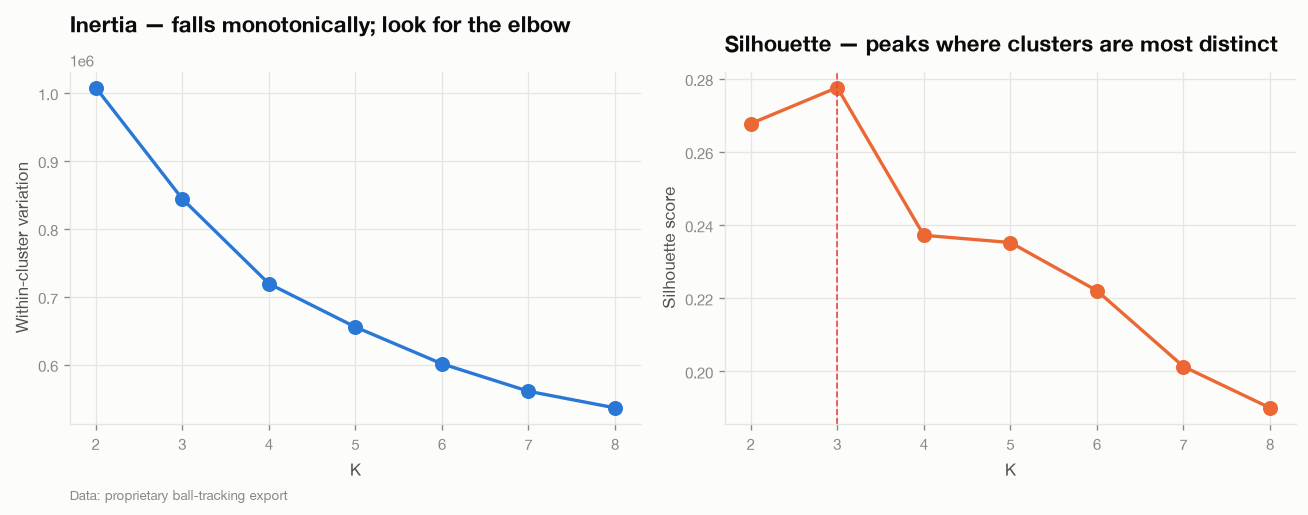

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].plot(curve.k, curve.inertia, marker="o")
axes[0].set_title("Inertia — falls monotonically; look for the elbow")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Within-cluster variation")

best_k = int(curve.loc[curve.silhouette.idxmax(), "k"])
axes[1].plot(curve.k, curve.silhouette, marker="o", color=CATEGORICAL[1])
axes[1].axvline(best_k, color=CATEGORICAL[7], linestyle="--", linewidth=1)
axes[1].set_title("Silhouette — peaks where clusters are most distinct")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Silhouette score")

fig.tight_layout()
annotate_source(axes[0], text="Data: proprietary ball-tracking export")
best_k

Drag $K$ below and watch both numbers move together. Fit on a
20,000-row sample so the slider stays responsive — the chosen $K$ above was
computed on the full dataset.

In [6]:
demo_idx = rng.choice(len(X), size=20_000, replace=False)
X_demo = X[demo_idx]
X_demo_2d = PCA(n_components=2, random_state=SEED).fit_transform(X_demo)

def explore(k=best_k):
    labels = KMeans(n_clusters=k, random_state=SEED, n_init=5).fit_predict(X_demo)
    _fig, ax = plt.subplots(figsize=(7, 5.5))
    for c in range(k):
        m = labels == c
        ax.scatter(
            X_demo_2d[m, 0], X_demo_2d[m, 1],
            s=6, alpha=0.5, color=CATEGORICAL[c % len(CATEGORICAL)], label=f"cluster {c}",
        )
    ax.set_title(f"K = {k}, PCA-projected (20,000-delivery sample)")
    ax.legend(markerscale=3, loc="upper right")
    plt.show()

_ = widgets.interact(explore, k=widgets.IntSlider(min=2, max=8, value=best_k, continuous_update=False))

interactive(children=(IntSlider(value=3, continuous_update=False, description='k', max=8, min=2), Output()), _…

## 6. Judge it

Fit the chosen $K$ on the full dataset, then check it two ways: does it
rediscover pace vs spin — the label withheld from training — and does it say
anything about what happens next?

In [7]:
final_km = KMeans(n_clusters=best_k, random_state=SEED, n_init=10).fit(X)
df = df.assign(cluster=final_km.labels_)

centres = df.groupby("cluster")[FEATURES].mean().round(2)
sizes = df["cluster"].value_counts(normalize=True).round(3).rename("share")
centres.join(sizes)

,release_speed_kph,swing_angle,deviation,bounce_position_x,stumps_position_y,bounce_angle,drop_angle,share
cluster,,,,,,,,
0,100.43,-0.70,1.44,7.15,0.00,11.20,-16.18,0.249
1,129.93,0.17,-0.01,6.40,-0.08,8.00,-12.10,0.518
2,89.07,1.12,-2.40,5.20,-0.08,11.33,-15.86,0.233


In [8]:
purity = pd.crosstab(df["cluster"], df["bowling_type"], normalize="index").round(3)
outcomes = df.groupby("cluster").agg(
    runs=("runs", "mean"), wicket_rate=("wicket", "mean"), deliveries=("runs", "size")
).round(3)
purity.join(outcomes)

,pace,spin,runs,wicket_rate,deliveries
cluster,,,,,
0,0.422,0.578,1.306,0.053,48422
1,0.971,0.029,1.301,0.050,100857
2,0.067,0.933,1.228,0.047,45313


**In prose.** Two of the three clusters are near-total rediscoveries of a label
they never saw: the ~130 kph, negligible-swing cluster is ~97% pace; the ~89 kph,
sharp-turn cluster is ~93% spin. That's the sanity check passing — if it hadn't
found pace and spin unprompted, nothing else it found would be worth trusting.

The third cluster is the interesting one: medium pace, moving off the seam, and
close to an even split between the two labels — deliveries a single pace/spin
dropdown genuinely can't describe. That's medium-pace cutters and brisk-armed
spin occupying the same physical envelope, which is exactly the kind of thing
clustering exists to surface: not a rediscovery of a label, but a gap in one.

The outcome differences are real but modest — a few points of wicket rate, a few
hundredths of a run per ball. Delivery type alone is a weak predictor of what
happens next; that's an honest result, not a failure of the method.

## 7. What it gets wrong

- **The only label available to check against is pace/spin.** Recovering it
  twice is reassuring, not proof — there is no ground truth to grade the *rest*
  of what K-means might be finding (a yorker vs. a length ball, both "pace").
  → *external validation against a richer label set*
- **$K$ was chosen by silhouette on a 10,000-row subsample**, for speed. It
  agrees with the full-data optimum here, but that agreement isn't guaranteed on
  a different season or a different tracking provider. → *re-running under
  cross-validation*
- **Standardising treats every feature as equally important.** Line and length
  matter enormously to a batter; here they get exactly the same vote as speed
  and swing, because that's what "distance" means numerically, not because
  that's what matters cricket-wise. → *feature weighting, domain-informed
  distance metrics*
- **A handful of physically impossible readings sit in the data untouched.**
  They're too rare to move the centroids here, but a provider whose sensor
  drifts more than this one would need those caught before trusting anything
  downstream. → *data validation as a modelling step, not an afterthought*
- **K-means assumes round, similarly-sized clusters.** Bowling styles have no
  reason to actually look like that — a genuinely bimodal pace cluster (new-ball
  swing vs. death-overs yorkers) would get flattened into one prototype. →
  *Gaussian mixture models, DBSCAN*
- **This cannot be re-run by anyone without this exact export.** The method
  generalises; the dataset does not. → `docs/data.md` documents the schema so a
  licensed or synthetic replacement slots in unchanged.

**Next:** a later lesson takes these seven features and asks whether they can be
compressed to two or three without losing what makes the clusters distinct —
PCA, and what "distance" even means in seven dimensions.

## Appendix — K-means from scratch (optional)

Everything above calls `sklearn.cluster.KMeans`. Same algorithm — Lloyd's
algorithm — written out, because watching it converge teaches more than reading
its name. Not one of the seven fixed sections above; skip it if the lesson has
already made its point.

In [9]:
def kmeans_from_scratch(X: np.ndarray, k: int, seed: int, max_iter: int = 100):
    """Assign, recompute, repeat until nothing moves. One random start."""
    local_rng = np.random.default_rng(seed)
    centroids = X[local_rng.choice(len(X), size=k, replace=False)]
    for _ in range(max_iter):
        # Assign: each point to its nearest centroid (squared Euclidean).
        distances = ((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)
        labels = distances.argmin(axis=1)
        # Recompute: each centroid becomes the mean of the points assigned to it.
        new_centroids = np.array([
            X[labels == c].mean(axis=0) if (labels == c).any() else centroids[c]
            for c in range(k)
        ])
        if np.allclose(new_centroids, centroids):
            break
        centroids = new_centroids
    inertia = ((X - centroids[labels]) ** 2).sum()
    return labels, inertia

# For understanding, not for 200,000 rows — a small sample keeps this readable.
scratch_sample = X[rng.choice(len(X), size=2_000, replace=False)]
labels_sklearn = KMeans(n_clusters=best_k, random_state=SEED, n_init=10).fit_predict(scratch_sample)

labels_one_start, inertia_one_start = kmeans_from_scratch(scratch_sample, k=best_k, seed=SEED)

# Cluster *labels* are arbitrary (this run's "0" isn't that run's "0"), so
# compare partitions, not label numbers, via the adjusted Rand index.
ari_one_start = adjusted_rand_score(labels_one_start, labels_sklearn)
print(f"one random start:   ARI = {ari_one_start:.3f}   inertia = {inertia_one_start:,.0f}")

one random start:   ARI = 0.396   inertia = 8,793


A single random start does **not** reliably match scikit-learn — Lloyd's
algorithm only ever improves on where it started, and where it started here
happened to be a worse basin. This is not a bug in the loop above; it is the
entire reason `KMeans` defaults to `n_init=10` rather than `n_init=1`. Restart a
few times and keep the lowest-inertia result:

In [10]:
best_labels, best_inertia = labels_one_start, inertia_one_start
for seed in range(1, 10):
    labels, inertia = kmeans_from_scratch(scratch_sample, k=best_k, seed=seed * 101)
    if inertia < best_inertia:
        best_labels, best_inertia = labels, inertia

ari_best = adjusted_rand_score(best_labels, labels_sklearn)
print(f"best of 10 starts:  ARI = {ari_best:.3f}   inertia = {best_inertia:,.0f}")
print("\nOne bad draw looked like a broken implementation. It was a missing "
      "n_init.")

best of 10 starts:  ARI = 1.000   inertia = 8,402

One bad draw looked like a broken implementation. It was a missing n_init.
